# Week 04 · Value Iteration, Asynchronous DP and Contraction — 가치 반복, 비동기 DP, 축약 사상

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/narame7/UOS-Reinforcement-Learning/blob/main/week04_dynamic_programming/03_value_iteration_async_contraction.ipynb)

슬라이드 **"Example: Shortest Path ($\gamma=1$)"**, **"Shortest Path: What One Sweep Actually Computes"**, **"Value Iteration"**의 표를 재현하고,
**"Asynchronous Dynamic Programming"**, **"In-Place Dynamic Programming"**, **"Prioritized Sweeping"**, **"Real-Time Dynamic Programming"**을
미로에서 동기식 가치 반복과 비교합니다. 마지막으로 **"Contraction Mapping"** 절의 부등식 $\|T(u)-T(v)\|_\infty\le\gamma\|u-v\|_\infty$와
기하급수적 수렴을 수치로 확인합니다.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# 공통 플롯 스타일 (모든 주차 노트북 동일)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_blue_red", ["#1c5cab", "#86b6ef", "#f0efec", "#f0a09f", "#b8302f"])
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.prop_cycle": mpl.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold",
})
np.set_printoptions(precision=2, suppress=True)
rng = np.random.default_rng(0)

# 이번 주 추가 import
import heapq
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

## 1. 최단 경로 문제의 가치 반복 (Example: Shortest Path ($\gamma=1$), Deterministic Value Iteration)

- $4\times4$ 격자, 왼쪽 위 칸 $g$가 유일한 목표(종단) 상태. 한 걸음마다 보상 $-1$, $\gamma=1$. 격자 밖으로 나가는 행동은 제자리.
- 가치 반복(value iteration): 벨만 최적 백업(Bellman optimality backup)을 모든 상태에 동기식으로 반복합니다.

$$v_{k+1}(s) = \max_{a}\Big[\mathcal R^a_s + \gamma\sum_{s'}\mathcal P^a_{ss'}v_k(s')\Big] = \max_{s'\in\text{neighbours}(s)}\big[-1 + v_k(s')\big]$$

슬라이드 표는 초기값을 $v_1\equiv 0$으로 부르고 $v_7$까지 보여 줍니다. 최적성의 원리(principle of optimality)에 따라
"이웃의 최적값을 알면 한 걸음 앞보기로 내 최적값을 안다"는 것이 이 식입니다.

In [2]:
SIZE = 4
GOAL = 0                                         # 왼쪽 위 칸 g
MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]       # up, right, down, left
MOVE_NAMES = ["up", "right", "down", "left"]


def sp_next(s, a):
    r, c = divmod(s, SIZE)
    r2, c2 = r + MOVES[a][0], c + MOVES[a][1]
    if not (0 <= r2 < SIZE and 0 <= c2 < SIZE):
        return s
    return r2 * SIZE + c2


def sp_value_iteration_sweep(v):
    """동기식 벨만 최적 백업 한 번: 새 배열에 쓰고, 목표 칸은 0으로 고정."""
    v_new = np.zeros_like(v)
    for s in range(SIZE * SIZE):
        if s == GOAL:
            continue
        v_new[s] = max(-1 + v[sp_next(s, a)] for a in range(4))
    return v_new


sp_v = {1: np.zeros(SIZE * SIZE)}                # 슬라이드 표기: v_1 = 0 (초기값)
for k in range(1, 7):
    sp_v[k + 1] = sp_value_iteration_sweep(sp_v[k])
print("v_7 =\n", sp_v[7].reshape(4, 4))

v_7 =
 [[ 0. -1. -2. -3.]
 [-1. -2. -3. -4.]
 [-2. -3. -4. -5.]
 [-3. -4. -5. -6.]]


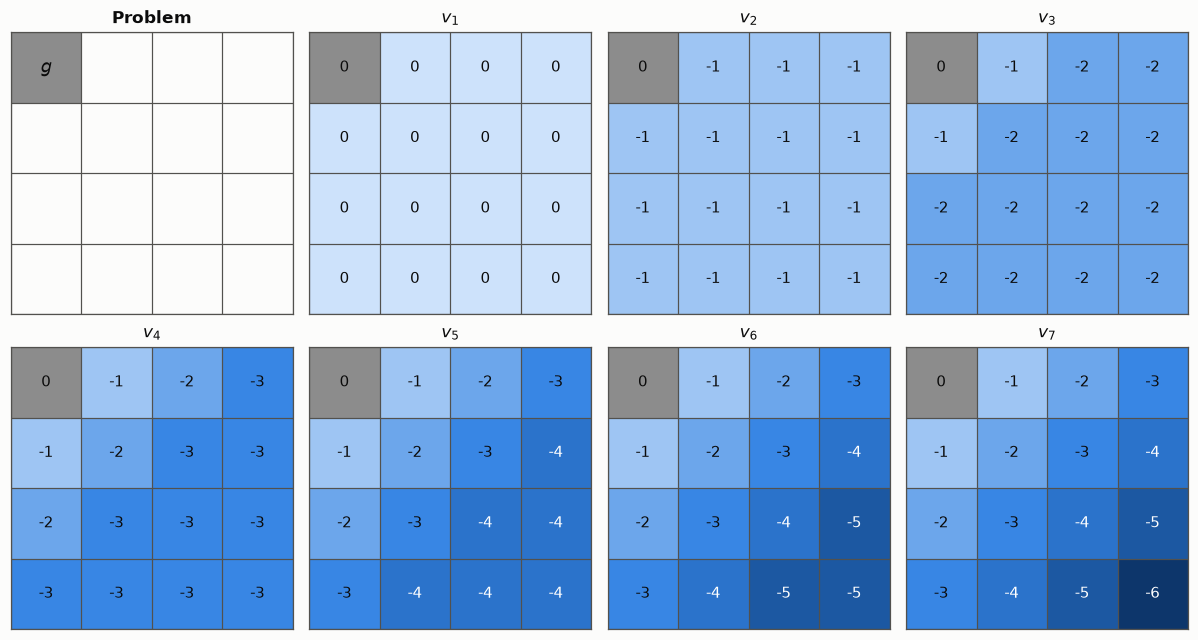

In [3]:
def draw_sp_grid(ax, v=None, title="", vmax=6):
    """최단 경로 격자: 목표 칸은 회색, 값은 |v| 크기로 색칠하고 정수로 표시."""
    ax.set_xlim(-0.5, SIZE - 0.5); ax.set_ylim(SIZE - 0.5, -0.5)
    ax.set_xticks(np.arange(-0.5, SIZE, 1), minor=True); ax.set_yticks(np.arange(-0.5, SIZE, 1), minor=True)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.grid(which="minor", color="#52514e", linewidth=0.8); ax.tick_params(which="both", length=0)
    for sp in ax.spines.values():
        sp.set_visible(True); sp.set_color("#52514e")
    ax.set_aspect("equal"); ax.set_title(title)
    if v is not None:
        ax.imshow(np.abs(v).reshape(SIZE, SIZE), cmap=SEQ_CMAP, vmin=0, vmax=vmax,
                  extent=(-0.5, SIZE - 0.5, SIZE - 0.5, -0.5))
    gr, gc = divmod(GOAL, SIZE)
    ax.add_patch(Rectangle((gc - 0.5, gr - 0.5), 1, 1, color="#8c8c8c"))
    for s in range(SIZE * SIZE):
        r, c = divmod(s, SIZE)
        if v is not None:
            dark = abs(v[s]) / vmax > 0.55 and s != GOAL
            ax.text(c, r, f"{v[s]:.0f}", ha="center", va="center", fontsize=10, color="white" if dark else "#0b0b0b")
        elif s == GOAL:
            ax.text(c, r, "g", ha="center", va="center", fontsize=12, style="italic")


fig, axes = plt.subplots(2, 4, figsize=(11, 6))
draw_sp_grid(axes[0, 0], None, "Problem")
for k in range(1, 8):
    ax = axes.flat[k]
    draw_sp_grid(ax, sp_v[k], f"$v_{k}$")
plt.tight_layout(); plt.show()

### 슬라이드와 비교
슬라이드 표(tex 990–1159행)를 그대로 옮겨 계산값과 **정확히** 같은지 확인합니다(정수이므로 허용 오차 0).

In [4]:
SLIDE_SP = {
    1: [[0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]],
    2: [[0, -1, -1, -1], [-1, -1, -1, -1], [-1, -1, -1, -1], [-1, -1, -1, -1]],
    3: [[0, -1, -2, -2], [-1, -2, -2, -2], [-2, -2, -2, -2], [-2, -2, -2, -2]],
    4: [[0, -1, -2, -3], [-1, -2, -3, -3], [-2, -3, -3, -3], [-3, -3, -3, -3]],
    5: [[0, -1, -2, -3], [-1, -2, -3, -4], [-2, -3, -4, -4], [-3, -4, -4, -4]],
    6: [[0, -1, -2, -3], [-1, -2, -3, -4], [-2, -3, -4, -5], [-3, -4, -5, -5]],
    7: [[0, -1, -2, -3], [-1, -2, -3, -4], [-2, -3, -4, -5], [-3, -4, -5, -6]],
}
for k in range(1, 8):
    ok = np.array_equal(sp_v[k].reshape(4, 4), np.array(SLIDE_SP[k], dtype=float))
    print(f"v_{k}: 계산값 == 슬라이드 ?  {ok}")
    assert ok
v_sp_next = sp_value_iteration_sweep(sp_v[7])
print("v_8 == v_7 (수렴) ?", np.array_equal(v_sp_next, sp_v[7]))

v_1: 계산값 == 슬라이드 ?  True
v_2: 계산값 == 슬라이드 ?  True
v_3: 계산값 == 슬라이드 ?  True
v_4: 계산값 == 슬라이드 ?  True
v_5: 계산값 == 슬라이드 ?  True
v_6: 계산값 == 슬라이드 ?  True
v_7: 계산값 == 슬라이드 ?  True
v_8 == v_7 (수렴) ? True


일곱 개 표가 모두 슬라이드와 정확히 같고, $v_7$에서 더 이상 바뀌지 않습니다(가장 먼 칸까지 6걸음이므로 초기값 포함 7개의 표).
최적 가치는 "목표까지 거리의 음수"입니다.

## 2. 한 번의 스윕이 실제로 계산하는 것 (Shortest Path: What One Sweep Actually Computes)

이 프레임은 초기값을 $V_0\equiv 0$이라고 부릅니다. 즉 **프레임의 $V_k$ = 앞 표의 $v_{k+1}$**입니다 (첨자만 하나 밀림).
프레임의 "Sweep 1: $V_1(s)=-1$ everywhere"는 목표 칸을 제외한 모든 칸을 뜻합니다(목표는 종단이라 0 유지, 앞 표의 $v_2$).
프레임의 계산을 코드로 한 줄씩 출력해 봅니다.

In [5]:
def explain_backup(V, s):
    """V_{k+1}(s) = max_a [-1 + V_k(s')] 를 이웃별로 풀어서 출력."""
    terms = []
    for a in range(4):
        s2 = sp_next(s, a)
        where = "g" if s2 == GOAL else ("stay" if s2 == s else f"cell {s2}")
        terms.append((-1 + V[s2], f"{MOVE_NAMES[a]}->{where}: -1 + ({V[s2]:.0f})"))
    best = max(t[0] for t in terms)
    return "max{ " + ",  ".join(t[1] for t in terms) + f" }} = {best:.0f}"


V0 = sp_v[1]                  # 프레임의 V_0
V1 = sp_v[2]                  # 프레임의 V_1
print("Sweep 1 (V_0 = 0)")
print("  cell 5 :", explain_backup(V0, 5))
print("Sweep 2")
print("  cell 1 (next to g)       :", explain_backup(V1, 1))
print("  cell 2 (two steps away)  :", explain_backup(V1, 2))

# 프레임의 일반 명제: 스윕 k번 후 V_k(s) = -min(거리(s), k)
dist = np.array([r + c for r, c in (divmod(s, SIZE) for s in range(SIZE * SIZE))])   # 목표가 (0,0)
for k in range(0, 7):
    assert np.array_equal(sp_v[k + 1], -np.minimum(dist, k).astype(float))
print("\n모든 k에 대해 V_k(s) = -min(steps to g, k) 확인 완료")

Sweep 1 (V_0 = 0)
  cell 5 : max{ up->cell 1: -1 + (0),  right->cell 6: -1 + (0),  down->cell 9: -1 + (0),  left->cell 4: -1 + (0) } = -1
Sweep 2
  cell 1 (next to g)       : max{ up->stay: -1 + (-1),  right->cell 2: -1 + (-1),  down->cell 5: -1 + (-1),  left->g: -1 + (0) } = -1
  cell 2 (two steps away)  : max{ up->stay: -1 + (-1),  right->cell 3: -1 + (-1),  down->cell 6: -1 + (-1),  left->cell 1: -1 + (-1) } = -2

모든 k에 대해 V_k(s) = -min(steps to g, k) 확인 완료


## 3. 가치 반복의 중간 값은 어떤 정책의 가치도 아니다 (Value Iteration)

슬라이드: *"Unlike policy iteration, value iteration does not require an explicit policy. Intermediate value functions may not correspond to any policy."*
예를 들어 $v_3$에서 오른쪽 아래 칸은 $-2$인데, 그 칸에서 목표까지는 최소 6걸음이므로 **어떤 정책**을 따라도 가치는 $-6$ 이하입니다
($v_\pi\le v_*$). 즉 $v_3$은 가치 반복의 중간 계산값일 뿐, 실제로 존재하는 정책의 가치가 아닙니다.

In [6]:
v_star_sp = sp_v[7]
print(" k | v_k(오른쪽 아래) | v*(오른쪽 아래) | v_k > v* 인 칸 수 (-> 어떤 정책의 가치도 될 수 없음)")
for k in range(1, 8):
    print(f"{k:2d} | {sp_v[k][15]:15.0f} | {v_star_sp[15]:15.0f} | {(sp_v[k] > v_star_sp).sum():3d}")

 k | v_k(오른쪽 아래) | v*(오른쪽 아래) | v_k > v* 인 칸 수 (-> 어떤 정책의 가치도 될 수 없음)
 1 |               0 |              -6 |  15
 2 |              -1 |              -6 |  13
 3 |              -2 |              -6 |  10
 4 |              -3 |              -6 |   6
 5 |              -4 |              -6 |   3
 6 |              -5 |              -6 |   1
 7 |              -6 |              -6 |   0


$v_k > v_*$인 칸이 하나라도 있으면 $v_k$는 어떤 정책의 가치도 아닙니다. 가치 반복은 정책 없이 $v_*$로 곧바로 다가가며,
정책은 마지막에 $v_*$에 대한 탐욕 정책으로 한 번 꺼내면 됩니다.

## 4. 동기식 vs 비동기식 DP (Asynchronous Dynamic Programming, In-Place DP, Prioritized Sweeping, Real-Time DP)

비동기식 방법의 차이가 잘 보이도록 조금 큰 미로(상태 102개)에서 비교합니다.

- 이동은 결정적, 벽/격자 밖으로 가면 제자리. 목표 `G`에 **도착할 때 보상 $+1$**, 그 외 0, $\gamma=0.95$ (교재의 미로 예제와 같은 형식).
  이때 $v_*(s)=\gamma^{d(s)-1}$ ($d(s)$ = 목표까지 걸음 수)입니다.
- 비교하는 방법 (모두 $V\equiv 0$에서 시작, 한 번의 "백업" = 한 상태의 벨만 최적 백업):
  1. **동기식(synchronous) 가치 반복**: 이전 값 $v_{old}$만 보고 모든 상태를 새 배열 $v_{new}$에 계산.
  2. **제자리(in-place) 가치 반복**: 배열 하나를 순서대로 덮어씀 — 방금 갱신한 값을 곧바로 사용. 순서 두 가지(행 우선 / 그 역순).
  3. **우선순위 스위핑(prioritized sweeping)**: 벨만 오차 $\Delta(s)=|v(s)-\max_a[\cdots]|$가 가장 큰 상태를 우선순위 큐(`heapq`)에서 꺼내 백업하고,
     그 상태의 **선행 상태(predecessor)**들의 $\Delta$를 다시 계산해 큐에 넣음.
  4. **실시간(real-time) DP**: 출발점 `S`에서 에이전트가 탐욕적으로 움직이며 **지나가는 상태만** 백업.
     RTDP는 초기값이 낙관적($V_0\ge v_*$)이어야 수렴이 보장되므로 $V_0\equiv 1$에서 시작합니다($v_*\le 1$).

In [7]:
MAZE = [
    "G...#.......",
    "....#..###..",
    ".##.#....#..",
    "..#.####.#..",
    "..#......#..",
    "..######.###",
    "........#...",
    "####.#..#...",
    "...#.#..#...",
    "...#.####...",
    "............",
    "...#......S.",
]
GAMMA_MAZE = 0.95
H, W = len(MAZE), len(MAZE[0])
cells = [(r, c) for r in range(H) for c in range(W) if MAZE[r][c] != "#"]
cell_index = {rc: i for i, rc in enumerate(cells)}
n_states = len(cells)
goal = next(i for i, (r, c) in enumerate(cells) if MAZE[r][c] == "G")
start = next(i for i, (r, c) in enumerate(cells) if MAZE[r][c] == "S")

NEXT = np.zeros((n_states, 4), dtype=int)       # NEXT[s, a] = 다음 상태
for i, (r, c) in enumerate(cells):
    for a, (dr, dc) in enumerate(MOVES):
        NEXT[i, a] = cell_index.get((r + dr, c + dc), i)   # 벽이나 격자 밖 -> 제자리
REWARD = (NEXT == goal).astype(float)           # 목표에 도착하면 +1
NEXT[goal] = goal; REWARD[goal] = 0.0           # 목표는 종단(흡수) 상태

PRED = [set() for _ in range(n_states)]         # 선행 상태: s' 로 한 걸음에 올 수 있는 s
for s in range(n_states):
    for a in range(4):
        if NEXT[s, a] != s:
            PRED[NEXT[s, a]].add(s)


def backup(V, s):
    """상태 s 하나의 벨만 최적 백업 값."""
    if s == goal:
        return 0.0
    return np.max(REWARD[s] + GAMMA_MAZE * V[NEXT[s]])


# 기준 v*: 동기식 가치 반복을 끝까지
v_star = np.zeros(n_states)
while True:
    v_new = np.max(REWARD + GAMMA_MAZE * v_star[NEXT], axis=1); v_new[goal] = 0.0
    if np.abs(v_new - v_star).max() < 1e-14:
        break
    v_star = v_new
steps_to_goal = np.round(1 + np.log(np.where(v_star > 0, v_star, 1)) / np.log(GAMMA_MAZE)).astype(int)
steps_to_goal[goal] = 0
print(f"states: {n_states},  start -> goal: {steps_to_goal[start]} steps,  farthest state: {steps_to_goal.max()} steps")

states: 102,  start -> goal: 21 steps,  farthest state: 27 steps


네 가지 방법을 구현합니다. 모두 백업 횟수와 오차를 기록하고, 동기식/제자리/우선순위 스위핑은 **모든 상태**의 오차가 $10^{-6}$ 이하가 될 때까지,
RTDP는 출발 상태의 값이 $10^{-6}$ 이내로 맞을 때까지 돌립니다.

In [8]:
TOL = 1e-6


def new_log():
    return {"backups": [0], "err": [], "err_start": [], "count": np.zeros(n_states, dtype=int)}


def record(log, V, n_backups):
    log["backups"].append(n_backups)
    log["err"].append(np.abs(V - v_star).max())
    log["err_start"].append(abs(V[start] - v_star[start]))


def run_synchronous():
    V = np.zeros(n_states); log = new_log(); record(log, V, 0); log["backups"].pop(0)
    n = 0
    while log["err"][-1] >= TOL:
        V_new = np.array([backup(V, s) for s in range(n_states)])    # v_old 만 사용
        V = V_new; n += n_states; log["count"] += 1
        record(log, V, n)
    return log


def run_in_place(order):
    V = np.zeros(n_states); log = new_log(); record(log, V, 0); log["backups"].pop(0)
    n = 0
    while log["err"][-1] >= TOL:
        for s in order:
            V[s] = backup(V, s)                                      # 곧바로 덮어씀
            n += 1; log["count"][s] += 1
            record(log, V, n)
    return log


def run_prioritized_sweeping():
    V = np.zeros(n_states); log = new_log(); record(log, V, 0); log["backups"].pop(0)
    queue = []                                                       # (-Delta, state)
    for s in range(n_states):
        delta = abs(backup(V, s) - V[s])
        if delta > 1e-12:
            heapq.heappush(queue, (-delta, s))
    n = 0
    while queue:
        _, s = heapq.heappop(queue)
        new_value = backup(V, s)
        if abs(new_value - V[s]) <= 1e-12:                           # 이미 최신이면 건너뜀
            continue
        V[s] = new_value; n += 1; log["count"][s] += 1
        record(log, V, n)
        for p in PRED[s]:                                            # 영향받는 선행 상태의 Delta 갱신
            delta = abs(backup(V, p) - V[p])
            if delta > 1e-12:
                heapq.heappush(queue, (-delta, p))
    return log


def run_rtdp(seed=0, V0=1.0, max_episodes=10_000):
    rng = np.random.default_rng(seed)
    V = np.full(n_states, V0); V[goal] = 0.0
    log = new_log(); record(log, V, 0); log["backups"].pop(0)
    n = 0
    for episode in range(max_episodes):
        s = start
        while s != goal:
            q = REWARD[s] + GAMMA_MAZE * V[NEXT[s]]
            V[s] = q.max(); n += 1; log["count"][s] += 1              # 방문한 상태만 백업
            record(log, V, n)
            s = NEXT[s, rng.choice(np.flatnonzero(q >= q.max() - 1e-12))]   # 탐욕 행동 (동점은 무작위)
        if log["err_start"][-1] < TOL:
            break
    log["episodes"] = episode + 1
    return log


row_major = list(range(n_states))            # 왼쪽 위(목표 쪽)부터
logs = {
    "Synchronous VI": run_synchronous(),
    "In-place VI (row-major order)": run_in_place(row_major),
    "In-place VI (reverse order)": run_in_place(row_major[::-1]),
    "Prioritized sweeping": run_prioritized_sweeping(),
}
rtdp_logs = [run_rtdp(seed) for seed in range(10)]
logs["Real-time DP (V0 = 1)"] = rtdp_logs[0]

method                           | 전체 수렴까지 백업 | V(S)가 맞을 때까지 백업 | 한 번이라도 백업된 상태 수 (/102, 목표 포함)
Synchronous VI                   |              2754 |                   2142 |  102
In-place VI (row-major order)    |               816 |                    101 |  102
In-place VI (reverse order)      |              2244 |                   2042 |  102
Prioritized sweeping             |               101 |                     81 |  101
Real-time DP (V0 = 1)            |                 - |                   1614 |   64
RTDP, 10 seeds mean (min-max)    |                 - |       1596 (1570-1634) |  64.0 (64-64)


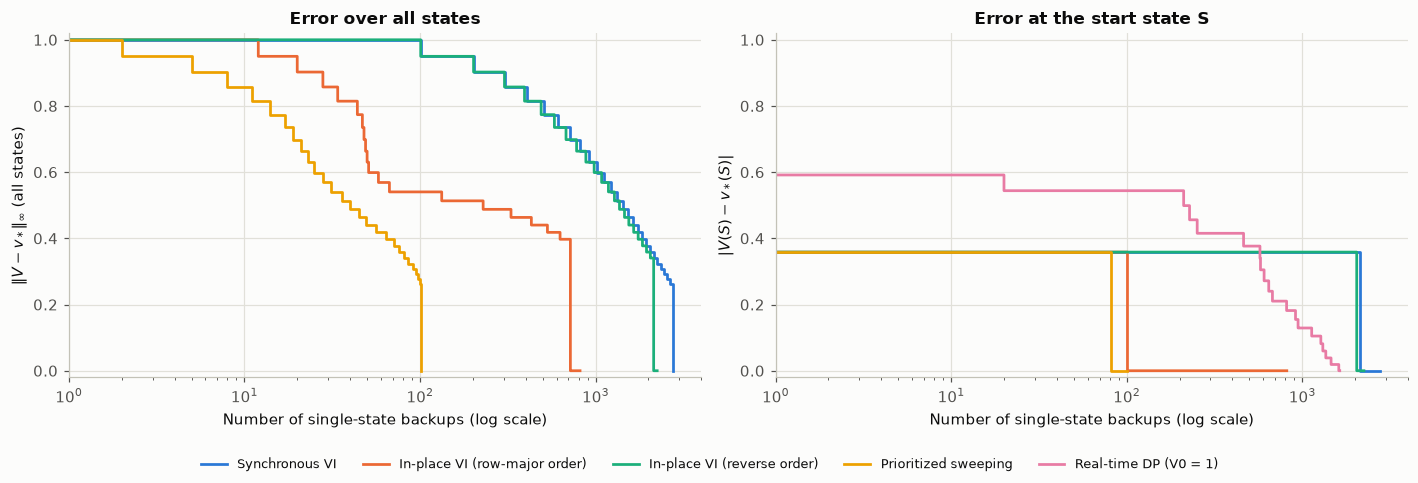

In [9]:
print(f"{'method':32s} | 전체 수렴까지 백업 | V(S)가 맞을 때까지 백업 | 한 번이라도 백업된 상태 수 (/{n_states}, 목표 포함)")
for name, log in logs.items():
    b = np.array(log["backups"])
    first_start = b[np.argmax(np.array(log["err_start"]) < TOL)]
    total = "-" if name.startswith("Real-time") else f"{b[-1]:d}"
    print(f"{name:32s} | {total:>17s} | {first_start:22d} | {int((log['count'] > 0).sum()):4d}")
rt_b = [log["backups"][-1] for log in rtdp_logs]
rt_t = [(log["count"] > 0).sum() for log in rtdp_logs]
print(f"{'RTDP, 10 seeds mean (min-max)':32s} | {'-':>17s} | {np.mean(rt_b):10.0f} ({min(rt_b)}-{max(rt_b)}) | "
      f"{np.mean(rt_t):5.1f} ({min(rt_t)}-{max(rt_t)})")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for i, (name, log) in enumerate(logs.items()):
    b = np.maximum(log["backups"], 1)
    if not name.startswith("Real-time"):
        axes[0].plot(b, log["err"], color=PALETTE[i], lw=1.8, drawstyle="steps-post")
    axes[1].plot(b, log["err_start"], color=PALETTE[i], lw=1.8, drawstyle="steps-post", label=name)
axes[0].set_ylabel(r"$\|V - v_*\|_\infty$ (all states)"); axes[0].set_title("Error over all states")
axes[1].set_ylabel(r"$|V(S) - v_*(S)|$"); axes[1].set_title("Error at the start state S")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlim(1, 4000); ax.set_ylim(-0.02, 1.02)
    ax.set_xlabel("Number of single-state backups (log scale)")
fig.legend(loc="lower center", ncol=5, fontsize=8.5)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

상태마다 **몇 번 백업되었는지**를 미로 위에 그리면 계산이 어디에 쓰였는지 보입니다(색은 로그 스케일, 흰 칸은 한 번도 백업되지 않은 상태).

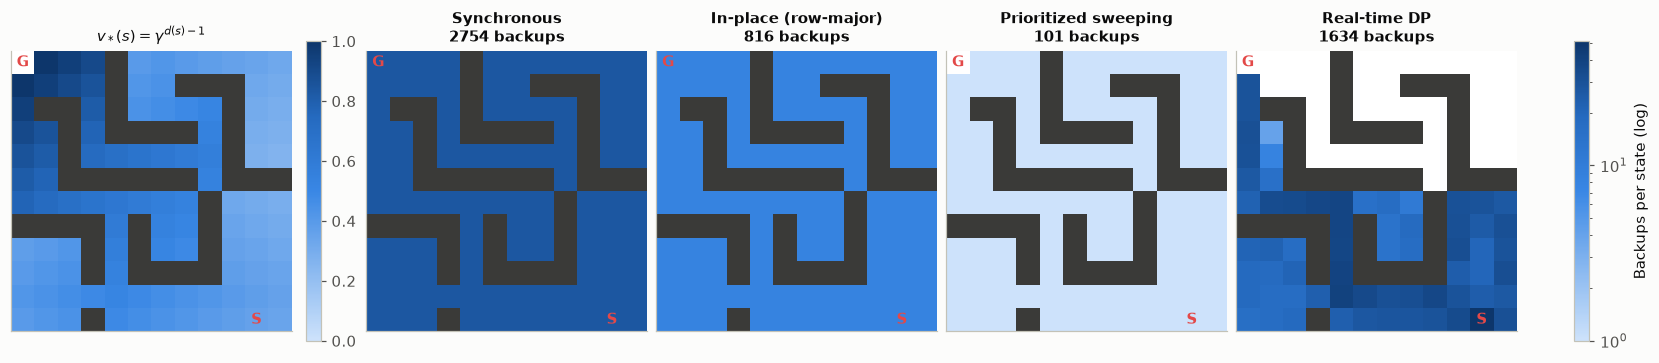

In [10]:
def draw_maze(ax, values=None, title="", norm=None, cmap=SEQ_CMAP):
    """미로 그림: 벽은 진한 회색, values(상태별 값)는 색으로. values가 0인 칸은 흰색."""
    grid = np.full((H, W), np.nan)
    if values is not None:
        for i, (r, c) in enumerate(cells):
            grid[r, c] = values[i] if values[i] > 0 else np.nan
    wall = np.array([[1.0 if MAZE[r][c] == "#" else np.nan for c in range(W)] for r in range(H)])
    ax.imshow(np.ones((H, W)), cmap=mpl.colors.ListedColormap(["#ffffff"]))
    ax.imshow(grid, cmap=cmap, norm=norm)
    ax.imshow(wall, cmap=mpl.colors.ListedColormap(["#3a3a38"]))
    for label, s in (("S", start), ("G", goal)):
        r, c = cells[s]
        ax.text(c, r, label, ha="center", va="center", fontsize=10, fontweight="bold", color="#e34948")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_title(title, fontsize=10)


count_norm = LogNorm(vmin=1, vmax=max(log["count"].max() for log in logs.values()))
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), constrained_layout=True)
draw_maze(axes[0], v_star, r"$v_*(s) = \gamma^{d(s)-1}$", norm=mpl.colors.Normalize(0, 1))
fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 1), cmap=SEQ_CMAP), ax=axes[0], shrink=0.8)
short = ["Synchronous", "In-place (row-major)", "Prioritized sweeping", "Real-time DP"]
for ax, name, title in zip(axes[1:], [n for n in logs if "reverse" not in n], short):
    log = logs[name]
    draw_maze(ax, log["count"], f"{title}\n{log['backups'][-1]} backups", norm=count_norm)
fig.colorbar(mpl.cm.ScalarMappable(norm=count_norm, cmap=SEQ_CMAP), ax=axes[1:], shrink=0.8,
             label="Backups per state (log)")
plt.show()

**해석**

- **동기식**: 모든 상태를 매 스윕 똑같이(스윕 수만큼) 백업합니다. 값이 목표에서 한 스윕에 한 칸씩만 퍼지므로, 가장 먼 상태까지의 걸음 수만큼 스윕이 필요합니다.
  $k$ 스윕 후 전체 오차는 정확히 $\gamma^k$(값이 아직 도달하지 않은 가장 가까운 상태의 $v_*$)이고, 가장 먼 상태까지 값이 도달하는 순간 0이 됩니다.
- **제자리**: 같은 스윕 안에서 방금 갱신한 값을 곧바로 쓰므로 훨씬 빠릅니다. 단 **순서가 중요**합니다. 목표에서 멀어지는 방향(행 우선)으로 훑으면
  한 스윕에 값이 여러 칸 퍼지고(출발 상태의 값은 첫 스윕에 이미 정답), 역순이면 동기식보다 조금 나은 정도입니다.
- **우선순위 스위핑**: 벨만 오차가 있는 곳(처음엔 목표 옆)부터 처리하고 그 선행 상태로 퍼져 나가므로, 이 결정적 미로에서는 **각 상태를 딱 한 번**
  백업하고 끝납니다(최단 경로의 Dijkstra 알고리즘과 같은 순서). 대신 선행 상태 정보(reverse dynamics)와 우선순위 큐가 필요합니다.
- **실시간 DP**: 출발점에서 실제로 걸어가며 지나간 상태만 백업하므로, 출발점과 무관한 막다른 구역(오른쪽 위 등)은 한 번도 백업하지 않습니다.
  대신 출발 상태의 값만 보장할 뿐 전체 $v_*$를 구하지는 않습니다. 이 작은 미로에서는 백업 수 자체의 이득이 크지 않지만,
  상태가 매우 많고 출발점에서 도달 가능한 부분이 작을 때 큰 차이를 냅니다.

## 5. 축약 사상 (Contraction Mapping)

슬라이드의 정리를 수치로 확인합니다. 가치 함수는 $|\mathcal S|$차원 벡터이고, 두 가치 함수의 거리는
$\|u-v\|_\infty=\max_s|u(s)-v(s)|$ (**Value Function $\infty$-Norm**)입니다.

- 벨만 기대 백업 $T^\pi(v)=\mathcal R^\pi+\gamma\mathcal P^\pi v$ 와 벨만 최적 백업 $T^*(v)=\max_a[\mathcal R^a+\gamma\mathcal P^a v]$는
  모두 $\gamma$-축약(contraction): $\|T(u)-T(v)\|_\infty\le\gamma\|u-v\|_\infty$.
- 축약 사상 정리(Contraction Mapping Theorem): 유일한 고정점($v_\pi$ 또는 $v_*$)으로 **선형 수렴률 $\gamma$**로 수렴.

무작위로 만든 MDP(상태 30개, 행동 4개, $\gamma=0.9$)에서 확인합니다.

T_pi  : max ratio = 0.900000  (gamma = 0.9),  median = 0.246
T_star: max ratio = 0.900000  (gamma = 0.9),  median = 0.288


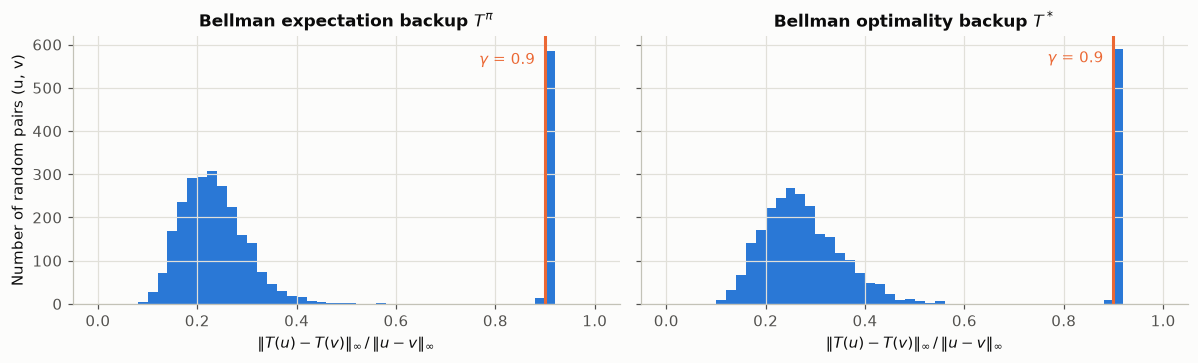

In [11]:
def random_mdp(n_states=30, n_actions=4, seed=1):
    """무작위 MDP: P[a, s, :] ~ Dirichlet, R[a, s] ~ U(-1, 1)."""
    g = np.random.default_rng(seed)
    P = g.dirichlet(0.3 * np.ones(n_states), size=(n_actions, n_states))
    R = g.uniform(-1, 1, size=(n_actions, n_states))
    return P, R


P_r, R_r = random_mdp()
GAMMA_R = 0.9
pi_r = np.random.default_rng(2).dirichlet(np.ones(4), size=30)        # 임의의 확률적 정책 pi[s, a]
R_pi_r = np.einsum("sa,as->s", pi_r, R_r)
P_pi_r = np.einsum("sa,ast->st", pi_r, P_r)


def T_pi(v, gamma=GAMMA_R):
    return R_pi_r + gamma * P_pi_r @ v


def T_star(v, gamma=GAMMA_R):
    return np.max(R_r + gamma * P_r @ v, axis=0)          # P_r @ v : (A, S)


def inf_norm(x):
    return np.abs(x).max()


g = np.random.default_rng(3)
ratios = {"T_pi": [], "T_star": []}
for i in range(3000):
    scale = 10 ** g.uniform(-1, 2)
    u = g.normal(0, scale, 30)
    v = u + g.normal(0, scale) if i % 5 == 0 else g.normal(0, scale, 30)   # 1/5은 "상수만큼 평행이동"한 쌍
    ratios["T_pi"].append(inf_norm(T_pi(u) - T_pi(v)) / inf_norm(u - v))
    ratios["T_star"].append(inf_norm(T_star(u) - T_star(v)) / inf_norm(u - v))
for key, r in ratios.items():
    r = np.array(r)
    print(f"{key:6s}: max ratio = {r.max():.6f}  (gamma = {GAMMA_R}),  median = {np.median(r):.3f}")
    assert r.max() <= GAMMA_R + 1e-12

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, (key, r), title in zip(axes, ratios.items(), [r"Bellman expectation backup $T^\pi$", r"Bellman optimality backup $T^*$"]):
    ax.hist(r, bins=np.linspace(0, 1, 51), color=PALETTE[0])
    ax.axvline(GAMMA_R, color=PALETTE[1], lw=2)
    ax.text(GAMMA_R - 0.02, ax.get_ylim()[1] * 0.9, r"$\gamma$ = 0.9", color=PALETTE[1], ha="right")
    ax.set_xlabel(r"$\|T(u)-T(v)\|_\infty \,/\, \|u-v\|_\infty$"); ax.set_title(title)
axes[0].set_ylabel("Number of random pairs (u, v)")
plt.tight_layout(); plt.show()

3000쌍 모두 비율이 $\gamma$ 이하입니다. 비율이 정확히 $\gamma$가 되는 경우는 $v=u+c\mathbf 1$처럼 **모든 상태를 같은 양만큼 옮긴** 쌍입니다
($\mathcal P^\pi\mathbf 1=\mathbf 1$이므로 $T(u+c\mathbf 1)=T(u)+\gamma c\mathbf 1$). 즉 부등식의 $\gamma$는 더 줄일 수 없는 값입니다.

### 가치 함수 공간에서 보기 (Value Function Space)
상태가 2개인 MDP라면 가치 함수는 평면 위의 점입니다. $\infty$-노름의 "공"은 정사각형이므로, 정사각형 테두리의 모든 가치 함수에
$T$를 반복 적용하면 그 모양이 매번 $\gamma$배 이하로 줄어들며 고정점으로 모입니다. (그림이 잘 보이도록 $\gamma=0.75$를 씁니다.)

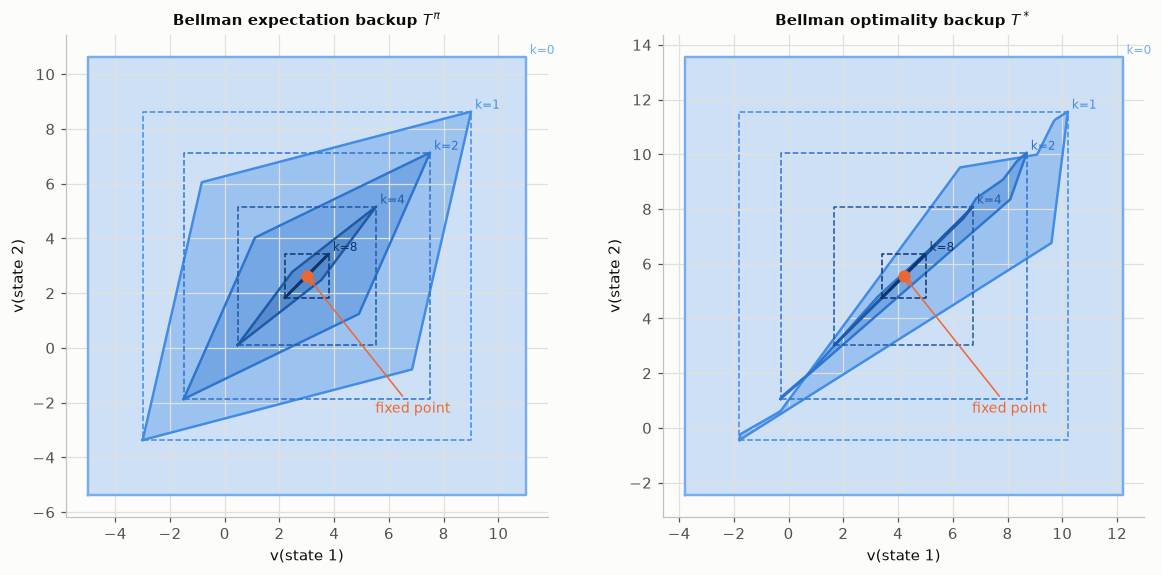

In [12]:
GAMMA_2 = 0.75
P2 = np.array([[[0.95, 0.05], [0.05, 0.95]],    # action 0 ("stay")
               [[0.3, 0.7], [0.6, 0.4]]])       # action 1 ("switch")
R2 = np.array([[1.0, 0.0],
               [0.0, 2.0]])
pi2 = np.array([[0.8, 0.2], [0.7, 0.3]])        # 대부분 stay 하는 확률적 정책
R_pi2 = np.einsum("sa,as->s", pi2, R2)
P_pi2 = np.einsum("sa,ast->st", pi2, P2)
ops2 = {
    r"Bellman expectation backup $T^\pi$": lambda v: R_pi2 + GAMMA_2 * P_pi2 @ v,
    r"Bellman optimality backup $T^*$": lambda v: np.max(R2 + GAMMA_2 * P2 @ v, axis=0),
}

t = np.linspace(0, 4, 401)[:-1]
unit_square = np.stack([np.interp(t, [0, 1, 2, 3, 4], [-1, 1, 1, -1, -1]),     # inf-노름 단위 공의 테두리
                        np.interp(t, [0, 1, 2, 3, 4], [-1, -1, 1, 1, -1])], axis=1)
RADIUS = 8.0
K_SHOW = [0, 1, 2, 4, 8]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, (title, T) in zip(axes, ops2.items()):
    fixed = np.zeros(2)
    for _ in range(500):
        fixed = T(fixed)                                   # 고정점 (v_pi 또는 v_*)
    pts = fixed + RADIUS * unit_square                     # ||v - fixed||_inf = 8 인 모든 가치 함수
    for k in range(K_SHOW[-1] + 1):
        if k in K_SHOW:
            shade = SEQ_CMAP(0.3 + 0.7 * K_SHOW.index(k) / (len(K_SHOW) - 1))
            closed = np.vstack([pts, pts[:1]])
            ax.fill(closed[:, 0], closed[:, 1], color=shade, alpha=0.35, lw=0)
            ax.plot(closed[:, 0], closed[:, 1], color=shade, lw=1.6)
            bound = fixed + RADIUS * GAMMA_2 ** k * np.vstack([unit_square, unit_square[:1]])
            ax.plot(bound[:, 0], bound[:, 1], "--", color=shade, lw=1)
            ax.text(*(fixed + RADIUS * GAMMA_2 ** k * np.array([1, 1])), f" k={k}", fontsize=8, color=shade,
                    va="bottom", ha="left")
        pts = np.array([T(p) for p in pts])
    ax.plot(*fixed, "o", color=PALETTE[1], ms=7)
    ax.annotate("fixed point", fixed, xytext=(fixed[0] + 2.5, fixed[1] - 5), fontsize=9, color=PALETTE[1],
                arrowprops=dict(arrowstyle="->", color=PALETTE[1], lw=1))
    ax.set_aspect("equal"); ax.set_title(title, fontsize=10)
    ax.set_xlabel("v(state 1)"); ax.set_ylabel("v(state 2)")
plt.tight_layout(); plt.show()

채워진 도형은 고정점에서 $\infty$-거리 8인 모든 가치 함수(정사각형 테두리)에 $T$를 $k$번 적용한 결과이고,
점선은 정리가 보장하는 영역 "고정점에서 $\infty$-거리 $8\gamma^k$ 이내"입니다. 두 연산자 모두 도형이 항상 점선 안에 있으며
고정점($v_\pi$ 또는 $v_*$)으로 모입니다. $T^\pi$는 아핀 사상이라 정사각형이 평행사변형이 되고, $T^*$는 max 때문에 조각별 선형이라 모양이 꺾입니다.
대각선 방향(두 상태를 같은 양만큼 옮기는 방향)으로는 정확히 $\gamma$배씩 줄어들어 점선에 닿습니다.

### 기하급수적 수렴과 유일한 고정점 (Contraction Mapping Theorem, Convergence of Iter. Policy Evaluation and Policy Iteration)
반복 정책 평가($T^\pi$ 반복)와 가치 반복($T^*$ 반복)의 오차를 로그 축으로 그리고, 정리가 주는 상한 $\gamma^k\|v_0-v_\text{fixed}\|_\infty$와 비교합니다.
오른쪽은 $\gamma$를 바꾸었을 때 가치 반복의 수렴 속도입니다.

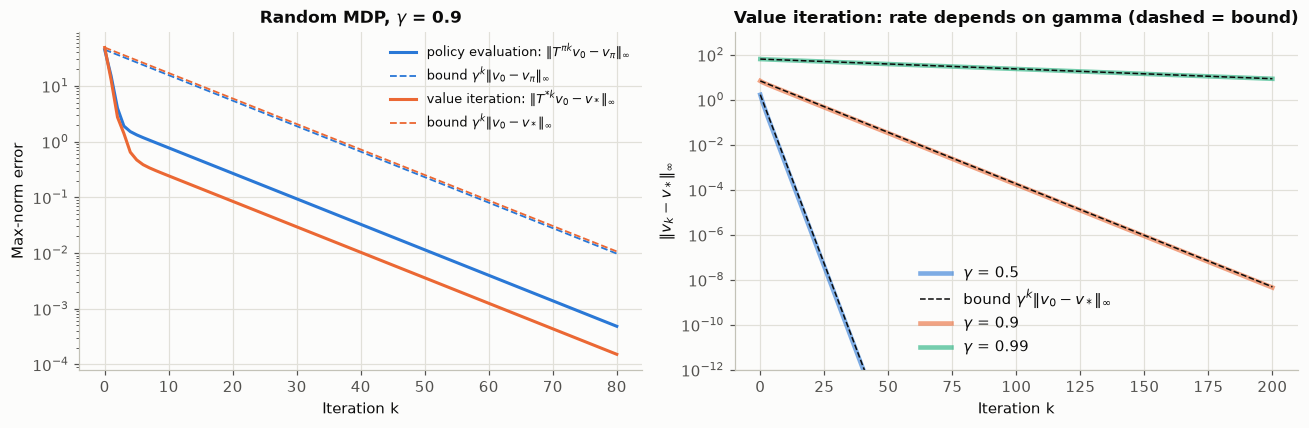

초기값 5개(표준편차 100)에서 출발한 가치 반복 결과의 최대 차이: 1.78e-15


In [13]:
def iterate(T, v0, n_iters):
    vs = [v0]
    for _ in range(n_iters):
        vs.append(T(vs[-1]))
    return np.array(vs)


v_pi_exact = np.linalg.solve(np.eye(30) - GAMMA_R * P_pi_r, R_pi_r)     # T^pi 의 고정점
v_star_r = iterate(T_star, np.zeros(30), 2000)[-1]                          # T^* 의 고정점

v0 = np.random.default_rng(4).normal(0, 20, 30)
ks = np.arange(81)
err_pe = [inf_norm(v - v_pi_exact) for v in iterate(T_pi, v0, 80)]
err_vi = [inf_norm(v - v_star_r) for v in iterate(T_star, v0, 80)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(ks, err_pe, color=PALETTE[0], label=r"policy evaluation: $\|T^{\pi k} v_0 - v_\pi\|_\infty$")
axes[0].semilogy(ks, err_pe[0] * GAMMA_R ** ks, "--", color=PALETTE[0], lw=1.2, label=r"bound $\gamma^k \|v_0 - v_\pi\|_\infty$")
axes[0].semilogy(ks, err_vi, color=PALETTE[1], label=r"value iteration: $\|T^{*k} v_0 - v_*\|_\infty$")
axes[0].semilogy(ks, err_vi[0] * GAMMA_R ** ks, "--", color=PALETTE[1], lw=1.2, label=r"bound $\gamma^k \|v_0 - v_*\|_\infty$")
axes[0].set_xlabel("Iteration k"); axes[0].set_ylabel("Max-norm error"); axes[0].set_title(r"Random MDP, $\gamma$ = 0.9")
axes[0].legend(fontsize=8.5)
for i, gam in enumerate([0.5, 0.9, 0.99]):
    vs_g = iterate(lambda v: T_star(v, gam), np.zeros(30), 3000)
    e = [inf_norm(v - vs_g[-1]) for v in vs_g[:201]]
    axes[1].semilogy(np.arange(201), np.maximum(e, 1e-16), color=PALETTE[i], lw=3, alpha=0.6, label=rf"$\gamma$ = {gam}")
    axes[1].semilogy(np.arange(201), e[0] * gam ** np.arange(201), "--", color="#0b0b0b", lw=1,
                     label=r"bound $\gamma^k\|v_0 - v_*\|_\infty$" if i == 0 else None)
axes[1].set_ylim(1e-12, 1e3)
axes[1].set_xlabel("Iteration k"); axes[1].set_ylabel(r"$\|v_k - v_*\|_\infty$")
axes[1].set_title("Value iteration: rate depends on gamma (dashed = bound)"); axes[1].legend()
plt.tight_layout(); plt.show()

for k, e_pe, e_vi in zip(ks, err_pe, err_vi):
    assert e_pe <= GAMMA_R ** k * err_pe[0] + 1e-9 and e_vi <= GAMMA_R ** k * err_vi[0] + 1e-9

# 유일한 고정점: 서로 다른 초기값 5개에서 출발해도 같은 v* 로
finals = [iterate(T_star, np.random.default_rng(10 + i).normal(0, 100, 30), 600)[-1] for i in range(5)]
spread = max(inf_norm(f - finals[0]) for f in finals)
print(f"초기값 5개(표준편차 100)에서 출발한 가치 반복 결과의 최대 차이: {spread:.2e}")
assert spread < 1e-9

두 오차 곡선 모두 상한(점선) 아래에서 기울기 $\log\gamma$ 이하로 직선적으로 줄어듭니다(선형 수렴률 $\gamma$).
오른쪽 그림($v_0=0$에서 시작)에서는 실선과 점선이 거의 겹치는데, 오차의 대부분이 "모든 상태에 공통인 상수 성분"이라
앞의 히스토그램에서 비율이 정확히 $\gamma$였던 쌍처럼 매번 정확히 $\gamma$배씩 줄기 때문입니다. 즉 이 상한은 느슨하지 않습니다.
$\gamma=0.99$이면 오차를 $10^{-6}$배 줄이는 데 약 $\ln 10^{6}/(1-\gamma)\approx 1400$번의 반복이 필요하므로, 할인율이 1에 가까운 문제에서
가치 반복이 느린 이유가 바로 이것입니다. 어떤 초기값에서 출발해도 같은 $v_*$에 도달하는 것은 고정점의 **유일성** 때문입니다.

## 직접 해보기

설정을 바꾸면 "슬라이드와 비교"의 `assert`가 실패할 수 있습니다(원래 설정 전용 검사이므로 정상입니다).

1. **최단 경로**: `GOAL`을 격자 가운데(예: 5)로 옮기면 필요한 표의 개수(스윕 수)는 몇 개가 되나요? "가장 먼 칸까지의 거리 + 1"과 비교해 보세요.
2. **제자리 DP의 순서**: `run_in_place`에 매 스윕 무작위로 섞은 순서(`rng.permutation(n_states)`)를 넣어 보세요. 행 우선과 역순 사이 어디쯤일까요?
3. **RTDP 초기값**: `run_rtdp(V0=0.0)`처럼 비관적 초기값으로 시작하면 어떤 일이 생기나요? 처음 찾은 경로에 갇혀 $V(S)$가 $v_*(S)$에 도달하지 못하는 시드를 찾아보세요.
4. **왜 $\infty$-노름인가**: 5절의 비율을 2-노름(`np.linalg.norm`)으로 계산해 보세요. $\gamma$보다 큰 비율이 나올 수 있습니다
   (힌트: $\mathcal P=\begin{bmatrix}1&0\\1&0\end{bmatrix}$, $x=(1,0)$이면 $\|\mathcal Px\|_2=\sqrt2\,\|x\|_2$). $\gamma=1$로 두면 비율은 어떻게 되나요?